In [1]:
%pip install pillow numpy pandas tqdm matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from tqdm.auto import tqdm

# Project paths
ROOT = Path(r"C:\projects\Final Year Project")
DATASET_ROOT = ROOT / "Dataset"

# Original datasets only
DOMAINS = {
    "Domain1_NLM": DATASET_ROOT / "Domain 1-NLM",
    "Domain2_Mendeley": DATASET_ROOT / "Domain 2-Mendeley"
}

# Output folders
OUTPUT_ROOT = ROOT / "Preprocessed_Dataset"
METADATA_DIR = ROOT / "Metadata"

IMAGE_SIZE = 512

VALID_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"
}

print("Dataset root exists:", DATASET_ROOT.exists())

for domain, path in DOMAINS.items():
    print(f"{domain}: {path.exists()} | {path}")

Dataset root exists: True
Domain1_NLM: True | C:\projects\Final Year Project\Dataset\Domain 1-NLM
Domain2_Mendeley: True | C:\projects\Final Year Project\Dataset\Domain 2-Mendeley


In [6]:
counts = []

for domain, domain_path in DOMAINS.items():

    for class_name in ["Normal", "Tuberculosis"]:

        class_path = domain_path / class_name

        if not class_path.exists():
            print("MISSING FOLDER:", class_path)
            continue

        image_files = [
            p for p in class_path.rglob("*")
            if p.is_file()
            and p.suffix.lower() in VALID_EXTENSIONS
        ]

        counts.append({
            "Domain": domain,
            "Class": class_name,
            "Image_Count": len(image_files)
        })

display(pd.DataFrame(counts))

,Domain,Class,Image_Count
0,Domain1_NLM,Normal,406
1,Domain1_NLM,Tuberculosis,394
2,Domain2_Mendeley,Normal,514
3,Domain2_Mendeley,Tuberculosis,2494


In [7]:
def preprocess_image(input_path, output_path, size=512):

    with Image.open(input_path) as img:

        # Correct image orientation
        img = ImageOps.exif_transpose(img)

        # Convert to 8-bit grayscale
        img = img.convert("L")

        # Pad to square without stretching the image
        width, height = img.size
        side = max(width, height)

        left = (side - width) // 2
        top = (side - height) // 2
        right = side - width - left
        bottom = side - height - top

        img = ImageOps.expand(
            img,
            border=(left, top, right, bottom),
            fill=0
        )

        # Resize for the initial PSPNet pipeline
        img = img.resize(
            (size, size),
            Image.Resampling.LANCZOS
        )

        output_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        img.save(output_path, format="PNG")

In [8]:
records = []
errors = []
image_number = 0

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

for domain, domain_path in DOMAINS.items():

    for class_name in ["Normal", "Tuberculosis"]:

        class_path = domain_path / class_name

        if not class_path.exists():
            raise FileNotFoundError(
                f"Required class folder not found: {class_path}"
            )

        image_files = [
            p for p in class_path.rglob("*")
            if p.is_file()
            and p.suffix.lower() in VALID_EXTENSIONS
        ]

        for input_path in tqdm(
            image_files,
            desc=f"{domain} / {class_name}"
        ):

            image_number += 1

            output_name = f"{image_number:06d}.png"

            output_path = (
                OUTPUT_ROOT
                / domain
                / class_name
                / output_name
            )

            try:
                preprocess_image(
                    input_path,
                    output_path,
                    IMAGE_SIZE
                )

                records.append({
                    "image_id": output_name,
                    "domain": domain,
                    "class_name": class_name,
                    "label": (
                        0 if class_name == "Normal" else 1
                    ),
                    "original_path": str(input_path.resolve()),
                    "processed_path": str(output_path.resolve()),
                    "width": IMAGE_SIZE,
                    "height": IMAGE_SIZE,
                    "channels": 1
                })

            except Exception as e:
                errors.append({
                    "image_path": str(input_path),
                    "error": str(e)
                })

metadata = pd.DataFrame(records)

metadata.to_csv(
    METADATA_DIR / "preprocessing_metadata.csv",
    index=False
)

pd.DataFrame(
    errors,
    columns=["image_path", "error"]
).to_csv(
    METADATA_DIR / "preprocessing_errors.csv",
    index=False
)

print("Successfully processed:", len(records))
print("Failed images:", len(errors))

display(
    pd.crosstab(
        metadata["domain"],
        metadata["class_name"]
    )
)

Domain2_Mendeley / Tuberculosis: 100%|██████████| 2494/2494 [01:19<00:00, 31.20it/s]


Successfully processed: 3808
Failed images: 0


class_name,Normal,Tuberculosis
domain,,
Domain1_NLM,406,394
Domain2_Mendeley,514,2494


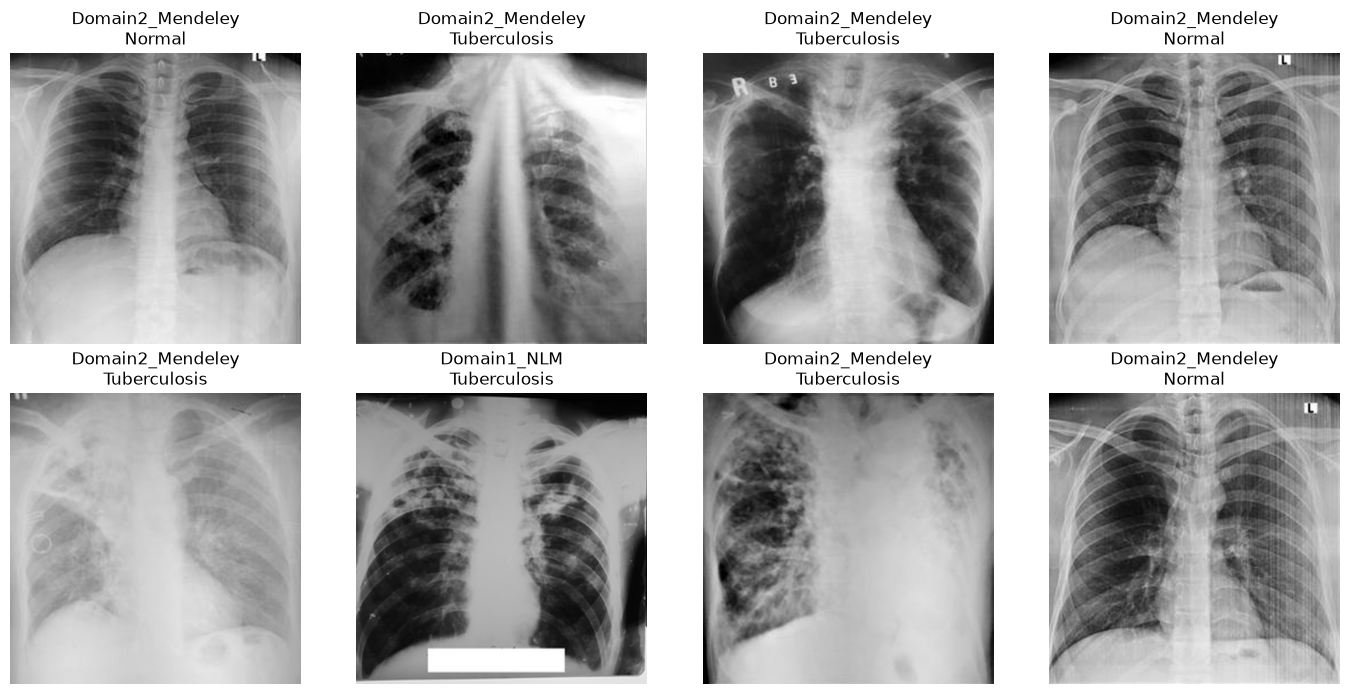

In [9]:
sample = metadata.sample(
    n=min(8, len(metadata)),
    random_state=42
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample.iterrows()):

    with Image.open(row["processed_path"]) as img:
        ax.imshow(img.copy(), cmap="gray", vmin=0, vmax=255)

    ax.set_title(
        f'{row["domain"]}\n{row["class_name"]}'
    )
    ax.axis("off")

for ax in axes[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
from collections import Counter

dimension_counts = Counter()

for path in tqdm(
    metadata["processed_path"],
    desc="Validating dimensions"
):

    with Image.open(path) as img:
        dimension_counts[img.size] += 1

print("Image dimensions:", dimension_counts)
print("Total metadata rows:", len(metadata))
print("Total output images:", sum(dimension_counts.values()))

assert all(
    dimensions == (512, 512)
    for dimensions in dimension_counts
), "Unexpected image dimensions found!"

assert len(metadata) == sum(dimension_counts.values()), (
    "Metadata and output counts do not match!"
)

print("Validation passed.")

Validating dimensions: 100%|██████████| 3808/3808 [00:37<00:00, 100.99it/s]

Image dimensions: Counter({(512, 512): 3808})
Total metadata rows: 3808
Total output images: 3808
Validation passed.
